In [1]:
!pip install nltk wordcloud

import nltk
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('omw-1.4')
print('All NLTK data downloaded successfully!')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\MSI\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\MSI\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\MSI\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\MSI\AppData\Roaming\nltk_data...
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\MSI\AppData\Roaming\nltk_data...


All NLTK data downloaded successfully!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 20 balanced movie reviews so 5-fold cross-validation runs cleanly out of the box
reviews = [
    ('This movie was absolutely fantastic! Best film of the year.', 'positive'),
    ('Terrible acting and boring plot. Complete waste of time!', 'negative'),
    ('Loved every minute of it. The director did an amazing job.', 'positive'),
    ('Awful storyline. I fell asleep halfway through.', 'negative'),
    ('Brilliant performances! The cinematography was breathtaking.', 'positive'),
    ('Worst movie I have ever seen. Do not waste your money.', 'negative'),
    ('Heartwarming and beautifully crafted. A true masterpiece.', 'positive'),
    ('Dull and predictable. The script was painfully bad.', 'negative'),
    ('An incredible thriller with outstanding acting and superb pacing.', 'positive'),
    ('Horrible dialogue and wooden characters. Completely disappointing.', 'negative'),
    ('A wonderful experience from start to finish. Highly recommended!', 'positive'),
    ('Painfully slow and poorly edited. I regret watching this.', 'negative'),
    ('Captivating story with emotional depth and great music.', 'positive'),
    ('Pathetic excuse for a comedy. Not a single funny moment.', 'negative'),
    ('Superb direction and phenomenal cast. Truly unforgettable cinema.', 'positive'),
    ('Boring, repetitive, and miserably acted. Avoid at all costs.', 'negative'),
    ('Uplifting, clever, and thoroughly entertaining throughout.', 'positive'),
    ('A total disaster with terrible visual effects and weak plot.', 'negative'),
    ('Phenomenal storytelling! Easily one of my favorite films ever.', 'positive'),
    ('Utter garbage. The worst screenplay I have encountered in years.', 'negative')
]

df = pd.DataFrame(reviews, columns=['review', 'sentiment'])

# Optional: If you downloaded the 50k Kaggle file into this folder, uncomment the line below:
# df = pd.read_csv('IMDB Dataset.csv')

print('Dataset shape:', df.shape)
print(df.head())

Dataset shape: (20, 2)
                                              review sentiment
0  This movie was absolutely fantastic! Best film...  positive
1  Terrible acting and boring plot. Complete wast...  negative
2  Loved every minute of it. The director did an ...  positive
3    Awful storyline. I fell asleep halfway through.  negative
4  Brilliant performances! The cinematography was...  positive


In [3]:
import re
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

def clean_text(text):
    text = re.sub(r'<[^>]+>', '', text)
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = text.lower().strip()
    return text

sample = 'The movie was AMAZING!!! Best film of 2024. Visit www.movies.com'
print('Original:', sample)
print('Cleaned :', clean_text(sample))

stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

words = ['running', 'happily', 'better', 'studies', 'caring', 'wolves']
print(f"\n{'Word':<15} {'Stemmed':<15} {'Lemmatized':<15}")
print('-' * 45)
for word in words:
    print(f"{word:<15} {stemmer.stem(word):<15} {lemmatizer.lemmatize(word, pos='v'):<15}")

Original: The movie was AMAZING!!! Best film of 2024. Visit www.movies.com
Cleaned : the movie was amazing best film of  visit

Word            Stemmed         Lemmatized     
---------------------------------------------
running         run             run            
happily         happili         happily        
better          better          better         
studies         studi           study          
caring          care            care           
wolves          wolv            wolves         


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

def preprocess_text(text):
    text = clean_text(text)
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in stop_words and len(t) > 2]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return ' '.join(tokens)

df['cleaned_review'] = df['review'].apply(preprocess_text)
df.dropna(subset=['cleaned_review'], inplace=True)

for i in range(3):
    print(f"Original: {df['review'].iloc[i]}")
    print(f"Cleaned : {df['cleaned_review'].iloc[i]}\n")

vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=1,
    max_df=0.95
)

X_tfidf = vectorizer.fit_transform(df['cleaned_review'])
print('Shape of TF-IDF matrix:', X_tfidf.shape)
print('Vocabulary size:', len(vectorizer.vocabulary_))
print('Sample feature names:', list(vectorizer.vocabulary_.keys())[:10])

Original: This movie was absolutely fantastic! Best film of the year.
Cleaned : movie absolutely fantastic best film year

Original: Terrible acting and boring plot. Complete waste of time!
Cleaned : terrible acting boring plot complete waste time

Original: Loved every minute of it. The director did an amazing job.
Cleaned : loved every minute director amazing job

Shape of TF-IDF matrix: (20, 203)
Vocabulary size: 203
Sample feature names: ['movie', 'absolutely', 'fantastic', 'best', 'film', 'year', 'movie absolutely', 'absolutely fantastic', 'fantastic best', 'best film']


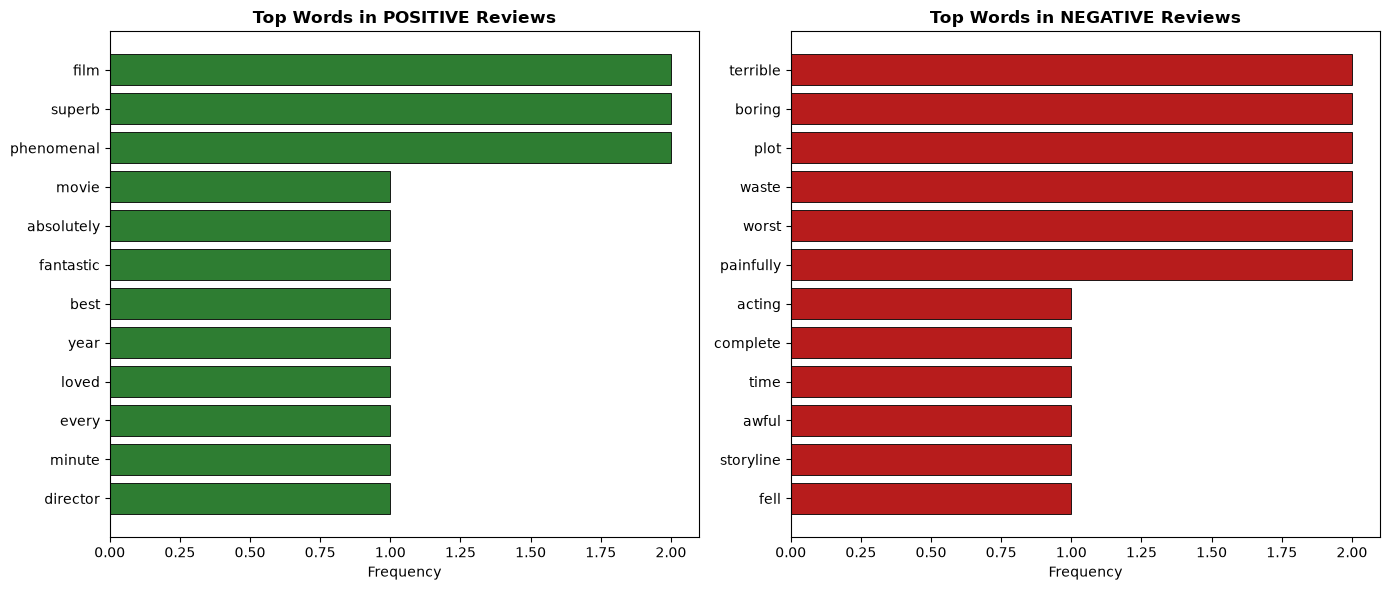

Chart saved: top_words_by_sentiment.png


In [5]:
from collections import Counter

def get_top_words(df_subset, n=12):
    all_words = ' '.join(df_subset['cleaned_review']).split()
    return Counter(all_words).most_common(n)

pos_words = get_top_words(df[df['sentiment'] == 'positive'])
neg_words = get_top_words(df[df['sentiment'] == 'negative'])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, words, title, color in [
    (axes[0], pos_words, 'Top Words in POSITIVE Reviews', '#2E7D32'),
    (axes[1], neg_words, 'Top Words in NEGATIVE Reviews', '#B71C1C')
]:
    ws = [w[0] for w in words]
    cs = [w[1] for w in words]
    ax.barh(ws[::-1], cs[::-1], color=color, edgecolor='black', linewidth=0.6)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Frequency', fontsize=10)

plt.tight_layout()
plt.savefig('top_words_by_sentiment.png', dpi=150)
plt.show()
print('Chart saved: top_words_by_sentiment.png')

Test Accuracy: 40.00%

Classification Report:
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00         3
    Positive       0.40      1.00      0.57         2

    accuracy                           0.40         5
   macro avg       0.20      0.50      0.29         5
weighted avg       0.16      0.40      0.23         5

ROC-AUC Score: 0.7500


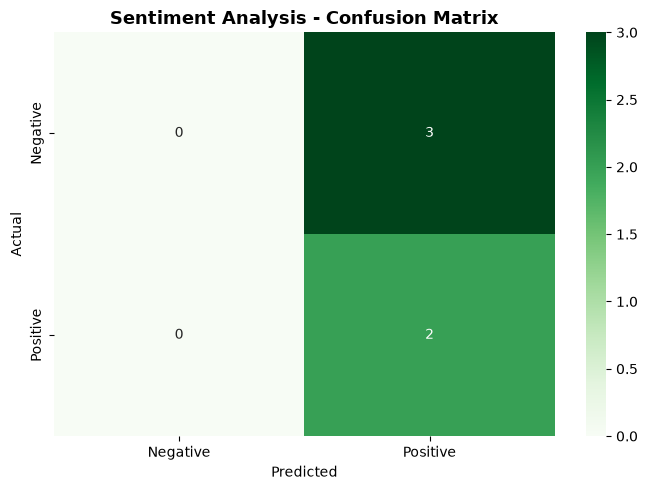

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

df['label'] = (df['sentiment'] == 'positive').astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    df['cleaned_review'],
    df['label'],
    test_size=0.25,
    random_state=42,
    stratify=df['label']
)

sentiment_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=10000, ngram_range=(1, 2), min_df=1, sublinear_tf=True)),
    ('clf', LogisticRegression(max_iter=500, C=1.0, random_state=42))
])

sentiment_pipeline.fit(X_train, y_train)
y_pred = sentiment_pipeline.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f'Test Accuracy: {accuracy * 100:.2f}%')
print('\nClassification Report:')
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive'], zero_division=0))

y_proba = sentiment_pipeline.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, y_proba)
print(f'ROC-AUC Score: {auc:.4f}')

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'], ax=ax)
ax.set_title('Sentiment Analysis - Confusion Matrix', fontsize=13, fontweight='bold')
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
plt.tight_layout()
plt.savefig('sentiment_confusion_matrix.png', dpi=150)
plt.show()

In [7]:
def predict_sentiment(review_text):
    cleaned = preprocess_text(review_text)
    prediction = sentiment_pipeline.predict([cleaned])[0]
    probabilities = sentiment_pipeline.predict_proba([cleaned])[0]
    label = 'POSITIVE' if prediction == 1 else 'NEGATIVE'
    confidence = max(probabilities) * 100
    print(f'Review    : {review_text[:65]}...')
    print(f'Prediction: {label} (Confidence: {confidence:.1f}%)')
    print(f'Positive  : {probabilities[1]*100:.1f}% | Negative: {probabilities[0]*100:.1f}%')
    print('-' * 60)

new_reviews = [
    'This film was absolutely incredible. The acting blew me away!',
    'Complete disaster. Worst screenplay I have ever encountered.',
    'Not bad, some good moments but overall quite mediocre.',
    'The visual effects were stunning and the story was captivating.',
    'I cannot believe how boring this was. Totally disappointed.'
]

for review in new_reviews:
    predict_sentiment(review)

Review    : This film was absolutely incredible. The acting blew me away!...
Prediction: POSITIVE (Confidence: 56.2%)
Positive  : 56.2% | Negative: 43.8%
------------------------------------------------------------
Review    : Complete disaster. Worst screenplay I have ever encountered....
Prediction: NEGATIVE (Confidence: 54.7%)
Positive  : 45.3% | Negative: 54.7%
------------------------------------------------------------
Review    : Not bad, some good moments but overall quite mediocre....
Prediction: POSITIVE (Confidence: 50.5%)
Positive  : 50.5% | Negative: 49.5%
------------------------------------------------------------
Review    : The visual effects were stunning and the story was captivating....
Prediction: POSITIVE (Confidence: 52.3%)
Positive  : 52.3% | Negative: 47.7%
------------------------------------------------------------
Review    : I cannot believe how boring this was. Totally disappointed....
Prediction: POSITIVE (Confidence: 50.8%)
Positive  : 50.8% | Negative: 

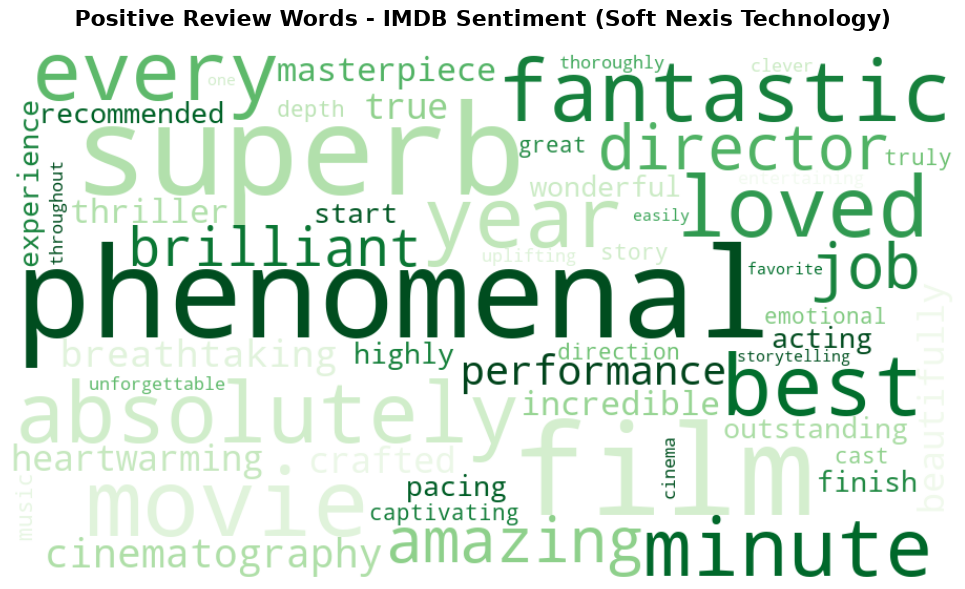

Saved: wordcloud_positive.png


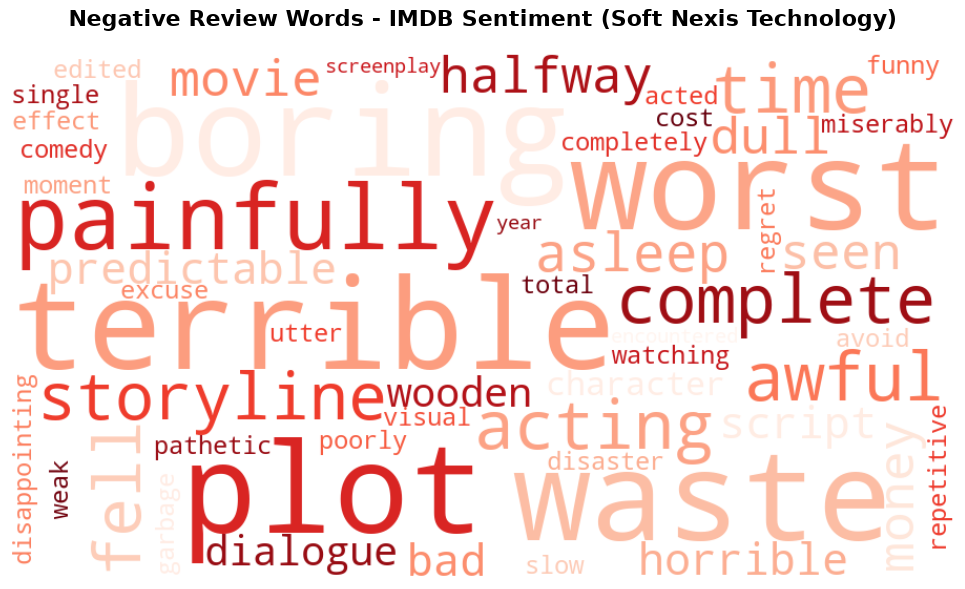

Saved: wordcloud_negative.png


In [8]:
from wordcloud import WordCloud

def generate_wordcloud(df_subset, title, colormap, filename):
    all_text = ' '.join(df_subset['cleaned_review'])
    wc = WordCloud(
        width=900,
        height=500,
        background_color='white',
        colormap=colormap,
        max_words=150,
        min_font_size=10,
        max_font_size=120,
        collocations=False
    ).generate(all_text)

    fig, ax = plt.subplots(figsize=(12, 6))
    ax.imshow(wc, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(title, fontsize=16, fontweight='bold', pad=20)
    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved: {filename}')

generate_wordcloud(
    df[df['sentiment'] == 'positive'],
    'Positive Review Words - IMDB Sentiment (Soft Nexis Technology)',
    'Greens',
    'wordcloud_positive.png'
)

generate_wordcloud(
    df[df['sentiment'] == 'negative'],
    'Negative Review Words - IMDB Sentiment (Soft Nexis Technology)',
    'Reds',
    'wordcloud_negative.png'
)

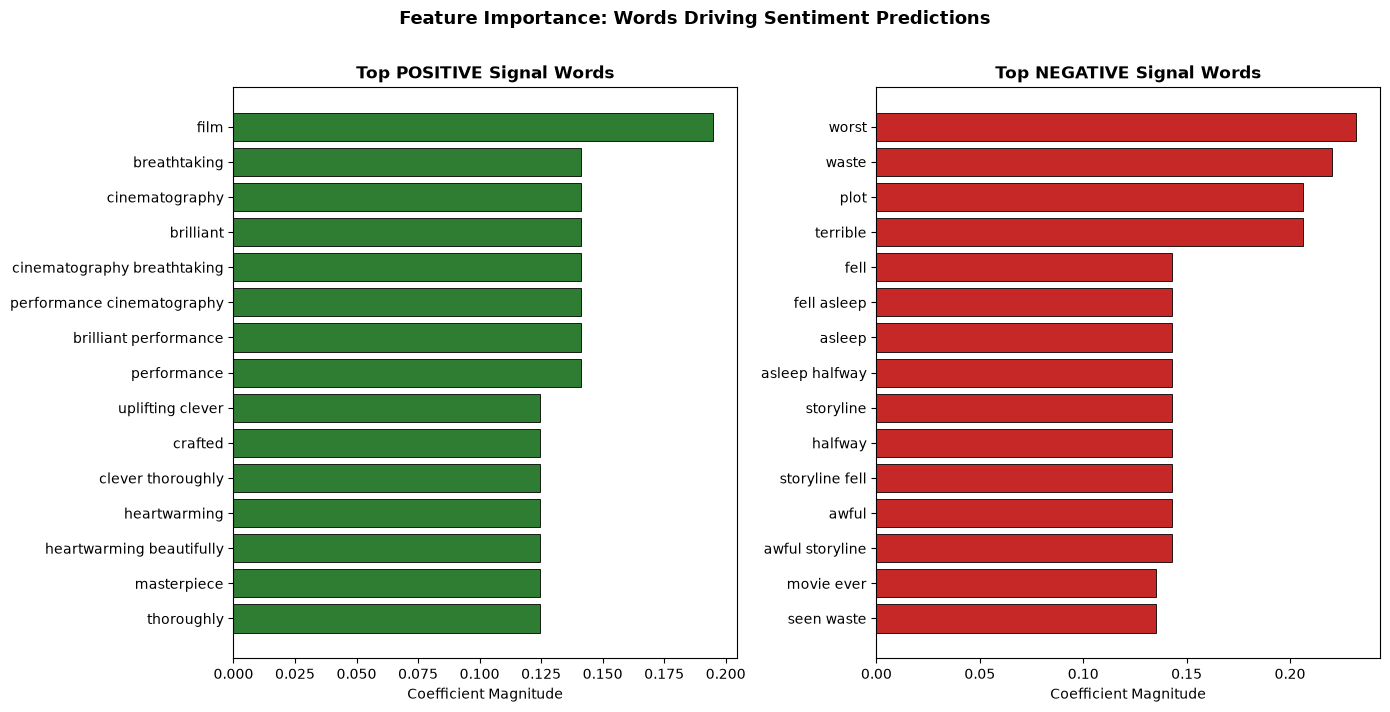

In [9]:
tfidf = sentiment_pipeline.named_steps['tfidf']
clf = sentiment_pipeline.named_steps['clf']

coefficients = clf.coef_[0]
feature_names = tfidf.get_feature_names_out()

top_n = min(15, len(coefficients) // 2)
pos_idx = np.argsort(coefficients)[-top_n:][::-1]
neg_idx = np.argsort(coefficients)[:top_n]

pos_words_imp = [(feature_names[i], coefficients[i]) for i in pos_idx]
neg_words_imp = [(feature_names[i], coefficients[i]) for i in neg_idx]

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, words, title, color in [
    (axes[0], pos_words_imp, 'Top POSITIVE Signal Words', '#2E7D32'),
    (axes[1], neg_words_imp, 'Top NEGATIVE Signal Words', '#C62828')
]:
    ws = [w[0] for w in words]
    cs = [abs(w[1]) for w in words]
    ax.barh(ws[::-1], cs[::-1], color=color, edgecolor='black', linewidth=0.6)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Coefficient Magnitude')

plt.suptitle('Feature Importance: Words Driving Sentiment Predictions',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('feature_importance_nlp.png', dpi=150, bbox_inches='tight')
plt.show()

Logistic Regression: mean=0.650 +/- 0.122
Naive Bayes: mean=0.600 +/- 0.122
Random Forest: mean=0.600 +/- 0.122


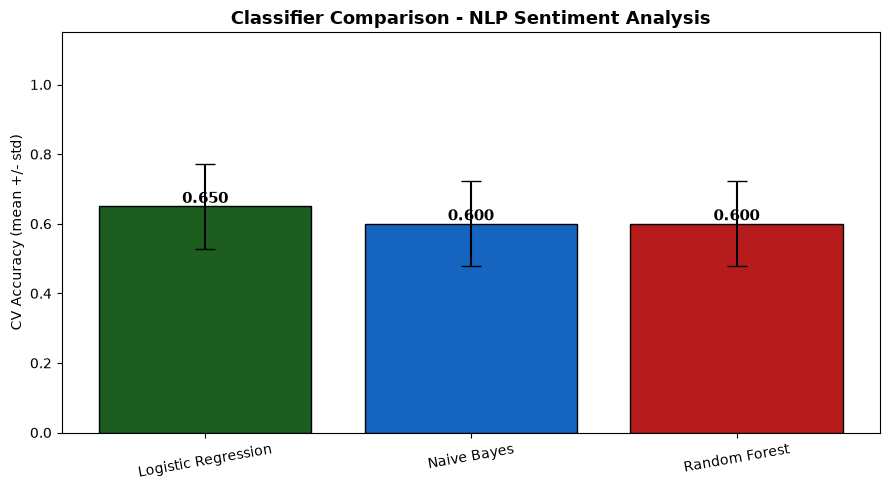

Model saved to sentiment_model.pkl
Loaded model says: POSITIVE
Model file size: 8.8 KB


In [10]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
import joblib
import os

tfidf_step = ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2)))

models = {
    'Logistic Regression': LogisticRegression(max_iter=300, random_state=42),
    'Naive Bayes': MultinomialNB(alpha=0.1),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
}

results = {}
for name, model in models.items():
    pipe = Pipeline([tfidf_step, ('clf', model)])
    scores = cross_val_score(pipe, df['cleaned_review'], df['label'], cv=5, scoring='accuracy')
    results[name] = scores
    print(f'{name}: mean={scores.mean():.3f} +/- {scores.std():.3f}')

fig, ax = plt.subplots(figsize=(9, 5))
names = list(results.keys())
means = [results[n].mean() for n in names]
stds = [results[n].std() for n in names]

bars = ax.bar(names, means, yerr=stds,
              color=['#1B5E20', '#1565C0', '#B71C1C'],
              edgecolor='black', capsize=7)

for bar, m in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
            f'{m:.3f}', ha='center', fontsize=11, fontweight='bold')

ax.set_ylim(0.0, 1.15)
ax.set_title('Classifier Comparison - NLP Sentiment Analysis', fontsize=13, fontweight='bold')
ax.set_ylabel('CV Accuracy (mean +/- std)')
plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig('nlp_model_comparison.png', dpi=150)
plt.show()

# Save the complete trained pipeline
joblib.dump(sentiment_pipeline, 'sentiment_model.pkl')
print('Model saved to sentiment_model.pkl')

loaded_model = joblib.load('sentiment_model.pkl')
test_review = [preprocess_text('This was an absolutely wonderful and magical experience!')]
result = loaded_model.predict(test_review)
print('Loaded model says:', 'POSITIVE' if result[0] == 1 else 'NEGATIVE')
print(f'Model file size: {os.path.getsize("sentiment_model.pkl") / 1024:.1f} KB')

Understanding TF-IDF and Real-World Applications of Sentiment Analysis

What is TF-IDF?
Machine learning algorithms cannot process raw text directly; words must first be converted into numerical vectors. TF-IDF—which stands for Term Frequency–Inverse Document Frequency—is a statistical technique that measures how important a specific word is to a single document relative to an entire collection (corpus) of documents. It combines two components:

Term Frequency (TF): Measures how frequently a word appears inside a single review. If a reviewer repeats the word "brilliant" three times, its TF score increases.

Inverse Document Frequency (IDF): Measures how rare or common that word is across all reviews in the dataset. Common domain words like "movie," "film," or "watch" appear in almost every review, so IDF scales their weight down near zero. Conversely, emotionally distinctive words like "masterpiece," "pathetic," or "breathtaking" appear in only a subset of reviews, giving them a high IDF weight.

By multiplying TF and IDF together, TF-IDF highlights the exact words that distinguish positive sentiment from negative sentiment while suppressing frequent filler vocabulary.

Two Real-World Applications of Sentiment Analysis

E-Commerce Product Quality & Brand Monitoring: Large retail platforms such as Amazon and Flipkart process millions of customer reviews daily. Sentiment analysis pipelines automatically classify incoming reviews, surface sudden spikes in negative sentiment around specific product batches (e.g., defective batteries or sizing issues), and extract key complaint keywords so product teams can resolve quality defects rapidly.

Customer Support Ticket Prioritization: Banks, telecom providers, and SaaS platforms receive thousands of support emails and live-chat messages every hour. By running real-time sentiment scoring on incoming messages, automated routing systems immediately flag high-frustration or angry customer tickets and escalate them to senior support agents, reducing customer churn and improving response times.